# Project Unit 1 y 2
# ISC. Jorge Antonio Toscano Lara

In [ ]:
import pandas as pd
import glob
import os
from functools import reduce

In [ ]:
# 1. Define mapping dictionaries for the files
file_value_col_map = {
    'Alcohol consumption.csv': ('RATE_PER_CAPITA_N', 'Alcohol_Consumption'),
    'Tobacco use.csv': ('PERCENT_POP_N', 'Tobacco_Use'),
    'Hypertension.csv': ('RATE_PER_100_N', 'Hypertension_Prev'),
    'Safely managed drinking water\u200b.csv': ('PERCENT_POP_N', 'Safely_Managed_Water'),
    'Adult obesity.csv': ('RATE_PER_100_N', 'Adult_Obesity'),
    'RELAY_WHS.csv': ('AMOUNT_N', 'Life_Expectancy')
}

dataframes_list = []

In [ ]:
# 2. Process Health indicators and Risk Factors
for file, (val_col, final_name) in file_value_col_map.items():
    try:
        df = pd.read_csv(file)

        # Filter for the United States (DIM_GEO_CODE_M49 == 840)
        df_usa = df[df['DIM_GEO_CODE_M49'] == 840].copy()

        # Filter totals (DIM_SEX == 'TOTAL' or DIM_SEX == 'BTSX' or DIM_DEG_URB == 'TOTAL')
        if 'DIM_SEX' in df_usa.columns:
             # Alcohol consumption, obesity, etc., use TOTAL or BTSX for both sexes
             df_usa = df_usa[df_usa['DIM_SEX'].isin(['TOTAL', 'BTSX'])]
        elif 'DIM_DEG_URB' in df_usa.columns:
             # Safely managed water is usually divided by urbanisation
             df_usa = df_usa[df_usa['DIM_DEG_URB'] == 'TOTAL']

        # Clean and rename
        df_clean = df_usa[['DIM_TIME', val_col]].rename(columns={
            'DIM_TIME': 'Year',
            val_col: final_name
        })

        df_clean = df_clean.drop_duplicates(subset=['Year'])
        dataframes_list.append(df_clean)
        print(f"Successfully processed: {file}")

    except Exception as e:
        print(f"Error processing {file}: {e}")

Successfully processed: Alcohol consumption.csv
Successfully processed: Tobacco use.csv
Successfully processed: Hypertension.csv
Successfully processed: Safely managed drinking water​.csv
Successfully processed: Adult obesity.csv
Successfully processed: RELAY_WHS.csv


In [ ]:
# 3. Process Causes of Death (GHE_FULL_DD.csv)
try:
    df_ghe = pd.read_csv('GHE_FULL_DD.csv')

    # Filter for USA and Totals (Both sexes)
    df_ghe_usa = df_ghe[(df_ghe['DIM_COUNTRY_CODE'] == 'USA') & (df_ghe['DIM_SEX_CODE'] == 'BTSX')].copy()

    # To simplify the general dataset, we will extract the death rate of the leading cause (Ischaemic heart disease)
    df_ghe_usa_heart = df_ghe_usa[df_ghe_usa['DIM_GHECAUSE_TITLE'] == 'Ischaemic heart disease']

    df_ghe_clean = df_ghe_usa_heart[['DIM_YEAR_CODE', 'VAL_DTHS_RATE100K_NUMERIC']].rename(columns={
        'DIM_YEAR_CODE': 'Year',
        'VAL_DTHS_RATE100K_NUMERIC': 'Ischaemic_Heart_Disease_Death_Rate'
    })

    df_ghe_clean = df_ghe_clean.drop_duplicates(subset=['Year'])
    dataframes_list.append(df_ghe_clean)
    print(f"Successfully processed: GHE_FULL_DD.csv")

except Exception as e:
    print(f"Error processing GHE_FULL_DD.csv: {e}")

Successfully processed: GHE_FULL_DD.csv


In [ ]:
# 4. Consolidation of all DataFrames
# We perform an outer merge to keep all reported years
df_consolidated = reduce(lambda left, right: pd.merge(left, right, on='Year', how='outer'), dataframes_list)

# Ensure the Year is the temporal index
df_consolidated['Year'] = pd.to_datetime(df_consolidated['Year'], format='%Y')
df_consolidated.set_index('Year', inplace=True)
df_consolidated.sort_index(inplace=True)

In [ ]:
# 5. Interpolation
# We fill gaps between annual measurements (critical for time series and models like ARIMA)
df_final = df_consolidated.interpolate(method='time')

# Filter from the year 2000 onwards
df_final = df_final[df_final.index.year >= 2000]

In [ ]:
# 6. Save the final dataset
df_final.to_csv('usa_health_dataset_final.csv')
print("\nFinal Consolidated Dataset exported as 'usa_health_dataset_final.csv'")


Final Consolidated Dataset exported as 'usa_health_dataset_final.csv'


In [ ]:
# 1. Load the previously generated dataset
df_clean = pd.read_csv('usa_health_dataset_final.csv')
df_clean['Year'] = pd.to_datetime(df_clean['Year'])
df_clean.set_index('Year', inplace=True)

# 2. Drop the ischaemic deaths variable (it only has 1 year of real data)
if 'Ischaemic_Heart_Disease_Death_Rate' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Ischaemic_Heart_Disease_Death_Rate'])

# 3. Trim the unrealistic future: Strictly filter up to 2021
df_clean = df_clean[df_clean.index.year <= 2021]

# 4. Backfill for Safely Managed Water (fills 2000-2004 with 2005 data)
df_clean['Safely_Managed_Water'] = df_clean['Safely_Managed_Water'].bfill()

# 5. Save the definitive dataset
df_clean.to_csv('usa_health_dataset_ready_for_eda.csv')

print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 22 entries, 2000-01-01 to 2021-01-01
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol_Consumption   22 non-null     float64
 1   Tobacco_Use           22 non-null     float64
 2   Hypertension_Prev     22 non-null     float64
 3   Safely_Managed_Water  22 non-null     float64
 4   Adult_Obesity         22 non-null     float64
 5   Life_Expectancy       22 non-null     float64
dtypes: float64(6)
memory usage: 1.2 KB
None


# Theoretical Justification
Given that the dataset comprises annual frequency records over a short period (2000-2021), the time series lacks the necessary granularity (monthly or quarterly) to decompose classic seasonal patterns. Extracting regular cyclical components is statistically unfeasible due to the irregularity of the periods at this macro scale. Therefore, the analysis focused on temporal dependence, deterministic trend, and autocorrelation using Lag Plots.

# ANALISIS EDA

# EDA ANALYSIS

Phase 1: Configuration and Data Loading
This stage simply prepares the working environment so that Python can process the information with the correct structure. It is summarised in two actions:

Tool preparation and design: We import the necessary libraries for calculation and plotting, and establish a professional visual template so the charts are ready for your report.

Temporal alignment: Upon reading the file, we directly convert the "Years" column into our data index. This is a fundamental requirement, as it indicates to the system that it is working with a chronological sequence rather than a standard static table.

In [ ]:
# --------------------------------------------------------
# PHASE 1: Configuration and Data Loading
# --------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

# Professional style configuration for the report
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Load the clean dataset we generated previously
# Ensure you have 'usa_health_dataset_ready_for_eda.csv' in the environment
df = pd.read_csv('usa_health_dataset_ready_for_eda.csv', index_col='Year', parse_dates=True)

# Phase 2: Longitudinal Trend Analysis
This stage creates a dual-axis chart to visually compare variables with different units of measurement (years versus percentages) on the same timeline.

Main axis (left): Maps life expectancy (blue line), facilitating the observation of its historical growth and the abrupt fall in the latest years of the record.

Secondary axis (right): Overlays the percentage rates of the risk factors. It allows for a direct contrast between the success in reducing smoking (green line) and the constant increase in obesity (red line).

The statistical objective of this visualisation is to cross-reference the behaviour of the target variable with its risk factors to easily detect structural breaks, divergences, or correlations over the two decades.

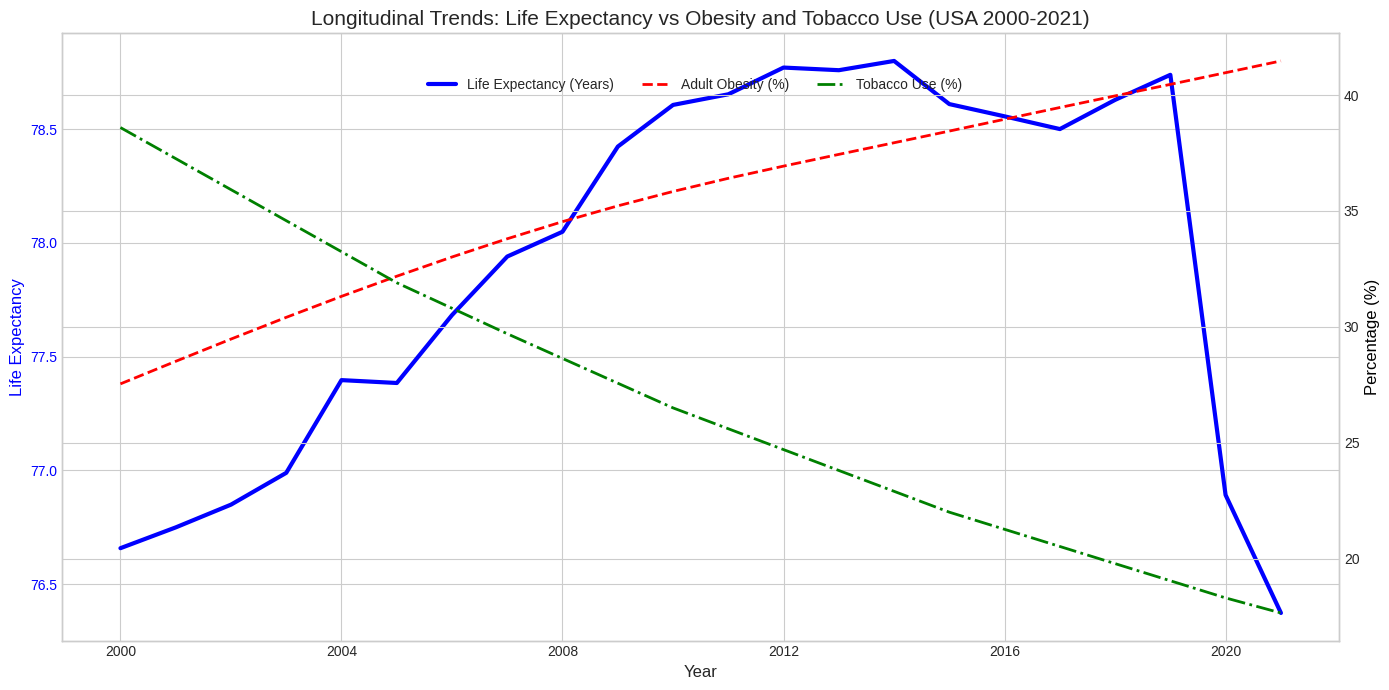

In [ ]:
# --------------------------------------------------------
# PHASE 2: Trend Analysis (Longitudinal Visualisation)
# --------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot Life Expectancy on the main axis
ax1.plot(df.index, df['Life_Expectancy'], color='blue', linewidth=3, label='Life Expectancy (Years)')
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Life Expectancy', color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

# Secondary axis for risk factors (Percentage scale)
ax2 = ax1.twinx()
ax2.plot(df.index, df['Adult_Obesity'], color='red', linewidth=2, linestyle='--', label='Adult Obesity (%)')
ax2.plot(df.index, df['Tobacco_Use'], color='green', linewidth=2, linestyle='-.', label='Tobacco Use (%)')
ax2.set_ylabel('Percentage (%)', color='black', fontsize=12)

plt.title('Longitudinal Trends: Life Expectancy vs Obesity and Tobacco Use (USA 2000-2021)', fontsize=15)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.9), ncol=3)
plt.tight_layout()
plt.show()

# Phase 3: Autocorrelation Analysis (Temporal Dependence)
This phase statistically evaluates how much the current life expectancy depends on its own values from previous years. It is summarised in two tools:

Lag Plots: These allow us to see historical patterns. The upward alignment of the dark and green points confirms that, historically, life expectancy grew steadily year on year. The main finding here is the yellow points (2020-2021), which fall abruptly and break the historical growth trend.

ACF Chart (Autocorrelation): This is the mathematical validation of the above. By observing that only "Lag 1" protrudes from the shaded area (the confidence interval), we conclude that the only year with strong and statistically significant predictive power over the current year is the immediately preceding year.

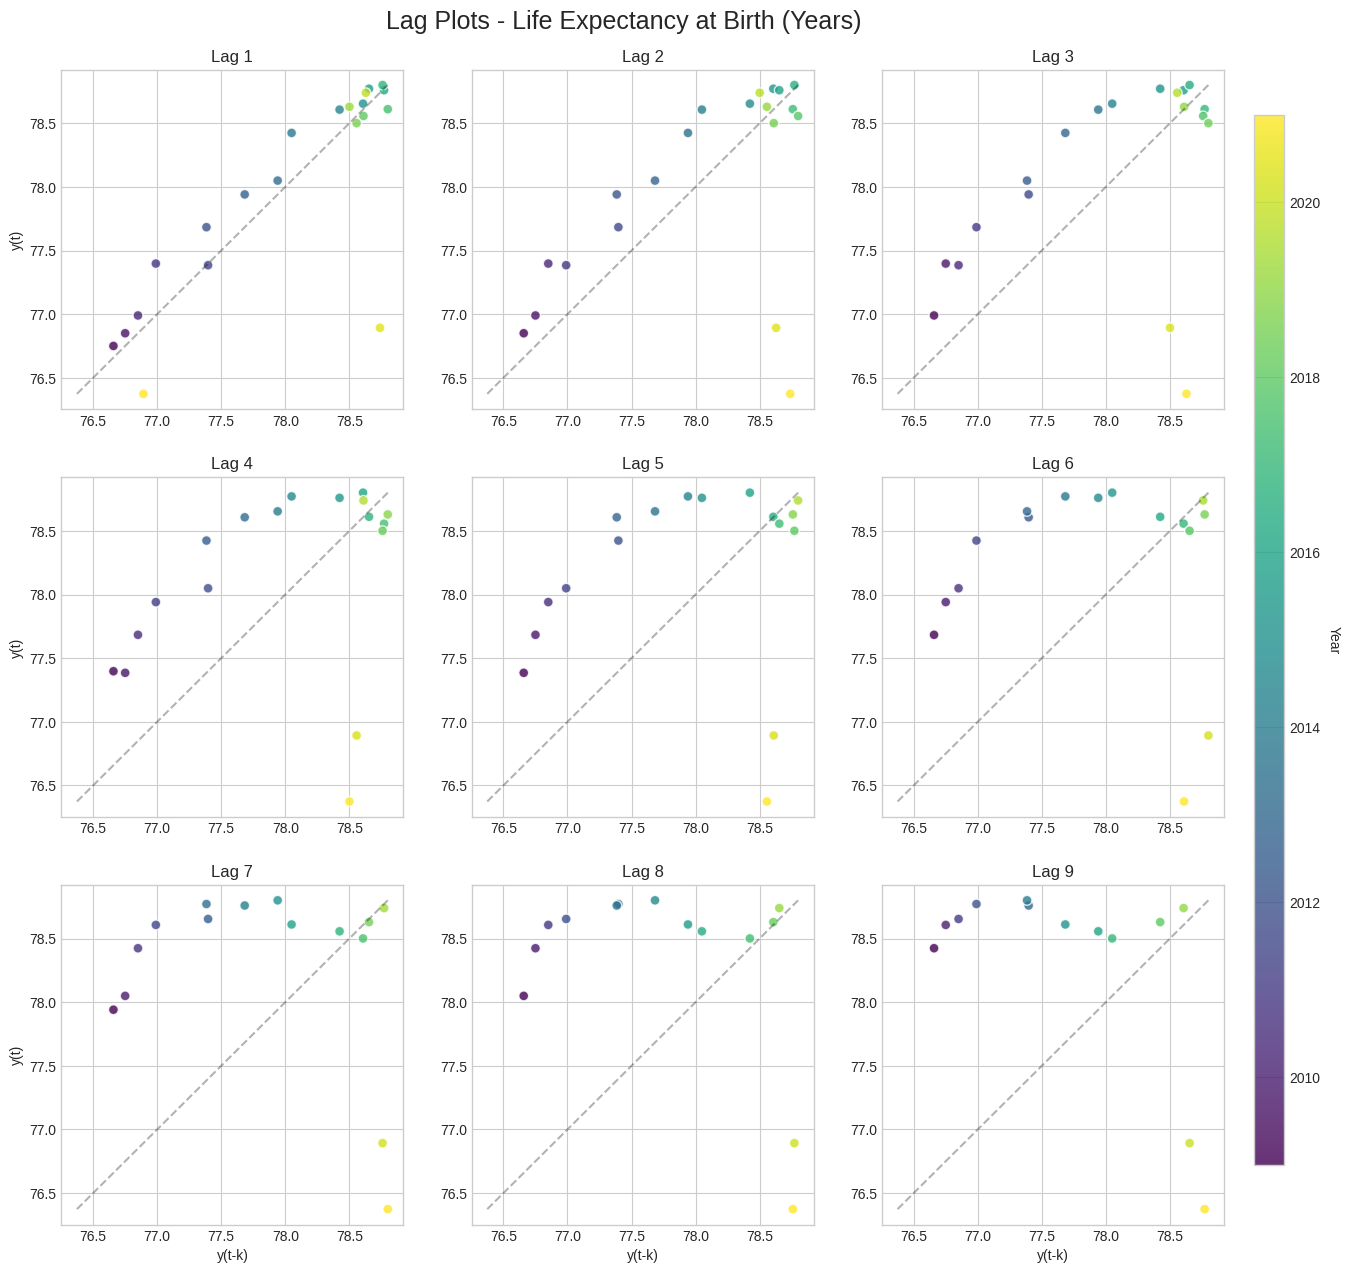

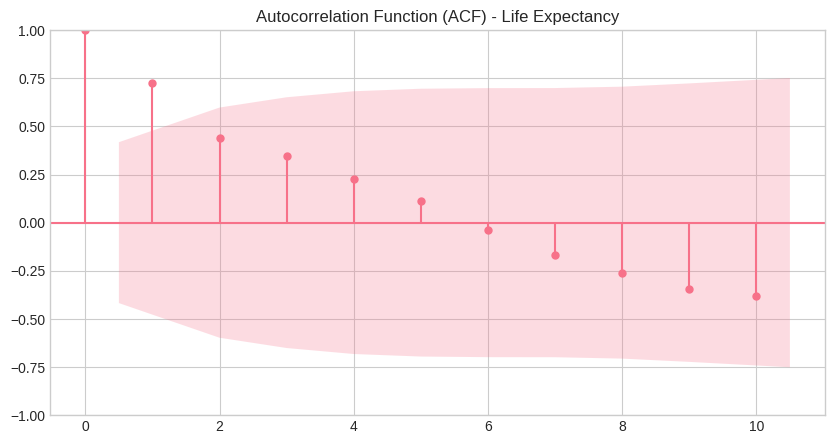

In [ ]:
# --------------------------------------------------------
# PHASE 3: Autocorrelation Analysis (Lag Plots)
# --------------------------------------------------------
# Replicating the analysis suggested by Dr Julio to evaluate temporal dependence

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle('Lag Plots - Life Expectancy at Birth (Years)', fontsize=18, y=0.92)

lags = range(1, 10)
colors = df.index.year # To colour by year and observe the evolution

for i, lag in enumerate(lags):
    row, col = divmod(i, 3)
    ax = axes[row, col]

    # Create the lag
    y = df['Life_Expectancy']
    y_lag = y.shift(lag)

    # Scatter plot coloured by year
    sc = ax.scatter(y_lag, y, c=colors, cmap='viridis', alpha=0.8, edgecolors='w', s=50)

    # Reference diagonal line (y = x)
    min_val = min(y.min(), y_lag.min())
    max_val = max(y.max(), y_lag.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.3)

    ax.set_title(f'Lag {lag}')
    if row == 2: ax.set_xlabel('y(t-k)')
    if col == 0: ax.set_ylabel('y(t)')

# Add colour bar for the years
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(sc, cax=cbar_ax)
cbar.set_label('Year', rotation=270, labelpad=15)

plt.show()

# We validate this numerically with the ACF (Autocorrelation Function) chart
fig, ax = plt.subplots(figsize=(10, 5))
plot_acf(df['Life_Expectancy'].dropna(), lags=10, ax=ax, title="Autocorrelation Function (ACF) - Life Expectancy")
plt.show()

# Phase 4: Cross-Correlation Matrix (Heatmap)
This final phase evaluates the statistical relationship between all the variables in your dataset using Spearman's rank correlation coefficient, which is ideal for discovering joint trends even if they are not strictly linear.

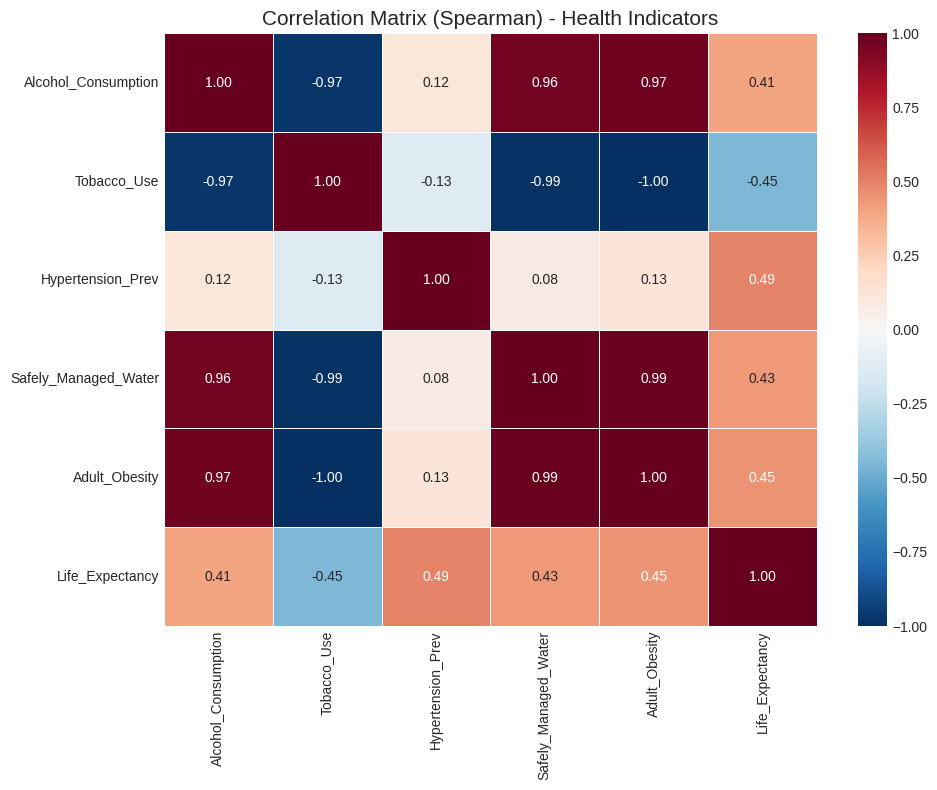

In [ ]:
# --------------------------------------------------------
# PHASE 4: Cross-Correlation (Heatmap)
# --------------------------------------------------------
plt.figure(figsize=(10, 8))
# We use Spearman's method as the relationships might not be strictly linear
corr_matrix = df.corr(method='spearman')

sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix (Spearman) - Health Indicators', fontsize=15)
plt.tight_layout()
plt.show()

Impact on Life Expectancy: We observe moderate relationships with the risk factors. For instance, there is a negative correlation (-0.45) with tobacco use, indicating that as tobacco consumption decreased historically, life expectancy tended to improve.

Spurious Correlation Warning: Extreme values are noted, such as -1.00 between Tobacco and Obesity, or 0.97 between Alcohol and Obesity. Both variables share a strong temporal trend (whilst one has steadily decreased over 20 years, the other has risen continuously), not because they have a direct cause-and-effect relationship.